In [22]:
import pandas as pd
import numpy as np
import biom

import os
from Bio import SeqIO
import matplotlib.pyplot as plt

### getting metadata_v2.csv project id

In [3]:
def find_folders_with_metadata(root_path):
    """
    Find all folders containing metadata_v2.csv under the specified path.
    :param root_path: The root directory path to search.
    :return: A list of folder names that contain metadata_v2.csv.
    """
    matched_folders = []

    for folder_name in os.listdir(root_path):
        folder_path = os.path.join(root_path, folder_name)
        
        if os.path.isdir(folder_path):
            metadata_path = os.path.join(folder_path, "metadata_v2.csv")
            if os.path.isfile(metadata_path):
                matched_folders.append(folder_name)

    return matched_folders

In [5]:
root_path = "../../data/projects"
project_id = find_folders_with_metadata(root_path)

In [6]:
pd.DataFrame(project_id).to_csv("../../data/project_list.txt", index=None, header=None)

In [7]:
len(project_id)

334

### Getting DADA2.biom

In [81]:
# for i in project_id:
#     biom_table = pd.read_csv(f"/beegfs/dongbiao/oral/{i}/results/ASVs_counts.tsv", sep="\t", index_col=0)
#     table = biom.Table(
#         data=biom_table.values,                       
#         observation_ids=biom_table.index.tolist(),      
#         sample_ids=biom_table.columns.tolist()    
#     )
    
#     output_path = f"/beegfs/dongbiao/oral/{i}/results/ASVs_counts.biom"
#     with biom.util.biom_open(output_path, 'w') as f:
#         table.to_hdf5(f, generated_by="pandas_to_biom")

In [83]:
for i in project_id:
    seq_dict = {}
    for record in SeqIO.parse(f"/beegfs/dongbiao/oral/{i}/results/ASVs.fa", "fasta"):
        seq_dict[record.id] = str(record.seq)
    biom_table = biom.load_table(f"/beegfs/dongbiao/oral/{i}/results/ASVs_counts.biom")
    biom_sid = biom_table.ids(axis="sample")

    metadata = pd.read_csv(f"../data/projects/{i}/metadata_v2.csv", dtype={"sample_id": str})
    metadata_sid = metadata.sample_id.values

    sid = np.intersect1d(biom_sid, metadata_sid)
    biom_table.filter(sid, axis="sample")
    updated_table = biom_table.update_ids(seq_dict, axis='observation', inplace=False)
    updated_table.remove_empty()
    with biom.util.biom_open(f"/beegfs/dongbiao/oral/{i}/results/DADA2.biom", 'w') as f:
        updated_table.to_hdf5(f, generated_by="fid_replacement")

In [11]:
metadata = pd.read_csv(f"../../data/projects/{project_id[0]}/metadata_v2.csv", dtype={"sample_id": str})

In [13]:
metadata.columns

Index(['Unnamed: 0', 'bioproject', 'sample_id', 'subject_id', 'age',
       'age_info', 'bmi', 'sex', 'platform', 'sequencing_region',
       'pcr_primers', 'country', 'site', 'site_group', 'disease_study',
       'status', 'title', 'public_time', 'matched_samples', 'is_time_series',
       'raw_subject_id', 'raw_status'],
      dtype='object')

In [12]:
metadata.head()

,Unnamed: 0,bioproject,sample_id,subject_id,age,age_info,bmi,sex,platform,sequencing_region,...,site,site_group,disease_study,status,title,public_time,matched_samples,is_time_series,raw_subject_id,raw_status
0,1,PRJNA362687,SRR5196331,H33,NaN,7-14,NaN,NaN,Illumina MiSeq,V3-V4,...,saliva,oral,yes,HC,Alterations of oral microbiota distinguish chi...,2017-01-28,no,no,H33-Sal,H
1,2,PRJNA362687,SRR5196332,H32,NaN,7-14,NaN,NaN,Illumina MiSeq,V3-V4,...,saliva,oral,yes,HC,Alterations of oral microbiota distinguish chi...,2017-01-28,no,no,H32-Sal,H
2,3,PRJNA362687,SRR5196333,H31,NaN,7-14,NaN,NaN,Illumina MiSeq,V3-V4,...,saliva,oral,yes,HC,Alterations of oral microbiota distinguish chi...,2017-01-28,no,no,H31-Sal,H
3,4,PRJNA362687,SRR5196334,H30,NaN,7-14,NaN,NaN,Illumina MiSeq,V3-V4,...,saliva,oral,yes,HC,Alterations of oral microbiota distinguish chi...,2017-01-28,yes,no,H30-Sal,H
4,5,PRJNA362687,SRR5196335,H29,NaN,7-14,NaN,NaN,Illumina MiSeq,V3-V4,...,saliva,oral,yes,HC,Alterations of oral microbiota distinguish chi...,2017-01-28,no,no,H29-Sal,H


### check the samples between DADA2.biom and metadata_v2.csv (sample_id)

In [85]:
results = []

for i in project_id: 
    
    biom_table = biom.load_table(f"/beegfs/dongbiao/oral/{i}/results/DADA2.biom")
    biom_sid = set(biom_table.ids(axis="sample"))
    
    metadata = pd.read_csv(f"../data/projects/{i}/metadata_v2.csv", dtype={"sample_id": str})
    metadata_sid = set(metadata.sample_id.values)
    
    matched       = biom_sid & metadata_sid          
    only_in_biom  = biom_sid - metadata_sid         
    only_in_meta  = metadata_sid - biom_sid          
    
    total_unique  = len(biom_sid | metadata_sid)    
    match_pct     = len(matched) / total_unique * 100 if total_unique > 0 else 0
    
    results.append({
        "project":            i,
        "biom_count":         len(biom_sid),
        "metadata_count":     len(metadata_sid),
        "matched_count":      len(matched),
        "match_pct":          round(match_pct, 2),
        "only_in_biom_count": len(only_in_biom),
        "only_in_meta_count": len(only_in_meta),
        "only_in_biom":       sorted(only_in_biom),  
        "only_in_meta":       sorted(only_in_meta),  
    })

In [86]:
results = pd.DataFrame(results)
results.sort_values("match_pct")

,project,biom_count,metadata_count,matched_count,match_pct,only_in_biom_count,only_in_meta_count,only_in_biom,only_in_meta
250,PRJEB29801,47,59,47,79.66,0,12,[],"[ERR2930088, ERR2930089, ERR2930094, ERR293009..."
265,PRJNA448135,115,120,115,95.83,0,5,[],"[SRR6918916, SRR6918930, SRR6918992, SRR691899..."
31,PRJNA232543,25,26,25,96.15,0,1,[],[SRR1060336]
333,PRJNA48333,7183,7447,7183,96.45,0,264,[],"[SRR041466, SRR041671, SRR041674, SRR041679, S..."
118,PRJNA853196,106,109,106,97.25,0,3,[],"[SRR19881802, SRR19881813, SRR19881828]"
...,...,...,...,...,...,...,...,...,...
112,PRJNA760654,166,166,166,100.00,0,0,[],[]
109,PRJEB40804,92,92,92,100.00,0,0,[],[]
108,PRJNA602902,119,119,119,100.00,0,0,[],[]
120,PRJNA649074,103,103,103,100.00,0,0,[],[]


In [53]:
### remove more samples from biom
# id_biom_sid_more = result_df.loc[(result_df['only_in_meta_count'] == 0) & (result_df['only_in_biom_count'] > 0)].project.values
# for i in id_biom_sid_more:
#     biom_table = biom.load_table(f"/beegfs/dongbiao/oral/{i}/results/DADA2.biom")
#     biom_sid = biom_table.ids(axis="sample")
    
#     metadata = pd.read_csv(f"../data/projects/{i}/metadata_v2.csv")
#     metadata_sid = metadata.sample_id.values
    
#     inter_sid = np.intersect1d(biom_sid, metadata_sid)
#     biom_table.filter(inter_sid, axis="sample")
#     biom_table.remove_empty()
#     with biom.util.biom_open(f"/beegfs/dongbiao/oral/{i}/results/DADA2.biom", 'w') as f:
#         biom_table.to_hdf5(f, generated_by="fid_replacement")

In [87]:
metadata_sid_more_project_id = results.loc[results.only_in_meta_count.values > 0].project.values
metadata_sid_more_project_id = metadata_sid_more_project_id[[i != "qiita_11404" for i in metadata_sid_more_project_id]]

In [89]:
len(metadata_sid_more_project_id)

54

In [90]:
metadata_sid_more_project_id

array(['PRJNA383868', 'PRJNA495719', 'PRJNA427101', 'PRJNA232543',
       'PRJNA451534', 'PRJEB6047', 'PRJNA380250', 'PRJEB24929',
       'PRJNA595346', 'PRJNA386665', 'PRJEB20890', 'PRJDB3518',
       'PRJNA420339', 'PRJEB27304', 'PRJEB5726', 'PRJNA647054',
       'PRJNA853196', 'PRJEB20889', 'PRJNA326441', 'PRJNA545251',
       'PRJEB69530', 'PRJEB20894', 'PRJEB19825', 'PRJNA417321',
       'PRJEB39420', 'PRJEB11419', 'PRJEB4953', 'PRJNA728576',
       'PRJEB20893', 'PRJNA352060', 'PRJEB19122', 'PRJEB11425',
       'PRJNA362643', 'PRJNA395436', 'PRJEB66628', 'PRJEB29801',
       'PRJNA391982', 'PRJNA325500', 'PRJEB6518', 'PRJNA503194',
       'PRJNA448135', 'PRJNA666891', 'PRJNA321349', 'PRJEB36860',
       'PRJNA414355', 'PRJEB33119', 'PRJNA847970', 'PRJDB5440',
       'PRJEB20891', 'PRJEB20892', 'PRJEB38062', 'PRJNA316469',
       'PRJEB1799', 'PRJNA48333'], dtype=object)

In [91]:
sra_results = []

for i in metadata_sid_more_project_id:
 
    metadata = pd.read_csv(f"../data/projects/{i}/metadata_v2.csv", dtype={"sample_id": str})
    metadata_sid = set(metadata.sample_id.values)

    sra_path = f"/beegfs/dongbiao/oral/{i}/sra"
    if os.path.exists(sra_path):
        sra_folders = set(os.listdir(sra_path))
    else:
        sra_folders = set()
    
    matched          = sra_folders & metadata_sid
    only_in_sra      = sra_folders - metadata_sid   
    only_in_metadata = metadata_sid - sra_folders   
    
    total_unique = len(sra_folders | metadata_sid)
    match_pct    = len(matched) / total_unique * 100 if total_unique > 0 else 0
    
    sra_results.append({
        "project":              i,
        "metadata_count":       len(metadata_sid),
        "sra_folder_count":     len(sra_folders),
        "matched_count":        len(matched),
        "match_pct":            round(match_pct, 2),
        "only_in_sra_count":    len(only_in_sra),
        "only_in_meta_count":   len(only_in_metadata),
        "only_in_sra":          sorted(only_in_sra),
        "only_in_metadata":     sorted(only_in_metadata),  
    })

In [92]:
sra_df = pd.DataFrame(sra_results)

# Overview
print(f"Total projects analyzed: {len(sra_df)}")
print(f"Fully matched (100%):    {(sra_df['match_pct'] == 100).sum()}")
print(f"Projects with missing downloads: {(sra_df['only_in_meta_count'] > 0).sum()}")
print(f"Projects with extra downloads:   {(sra_df['only_in_sra_count'] > 0).sum()}")

sra_df

Total projects analyzed: 54
Fully matched (100%):    50
Projects with missing downloads: 4
Projects with extra downloads:   0


,project,metadata_count,sra_folder_count,matched_count,match_pct,only_in_sra_count,only_in_meta_count,only_in_sra,only_in_metadata
0,PRJNA383868,540,540,540,100.00,0,0,[],[]
1,PRJNA495719,90,90,90,100.00,0,0,[],[]
2,PRJNA427101,1319,1319,1319,100.00,0,0,[],[]
3,PRJNA232543,26,26,26,100.00,0,0,[],[]
4,PRJNA451534,386,386,386,100.00,0,0,[],[]
5,PRJEB6047,72,72,72,100.00,0,0,[],[]
6,PRJNA380250,48,48,48,100.00,0,0,[],[]
7,PRJEB24929,231,231,231,100.00,0,0,[],[]
8,PRJNA595346,1834,1834,1834,100.00,0,0,[],[]
9,PRJNA386665,376,376,376,100.00,0,0,[],[]


These 4 projects showed incomplete downloads, where certain samples present in the metadata could not be retrieved. This discrepancy is not due to data processing errors, but rather **download failures during the `prefetch` step**. Specifically, some accession IDs could not be resolved within the SRA virtual file system, returning a `404` "name not found" error:

```
2026-05-11T06:51:00 prefetch.3.0.0 err: name not found while resolving query
within virtual file system module - failed to resolve accession 'ERR2930136'
- no data ( 404 )
```

This indicates that the raw sequencing data for these accessions is either **no longer publicly available**, has been removed, or was never properly deposited in the SRA database. Consequently, these samples are excluded from downstream analysis due to inaccessible source data, rather than any quality-based filtering.

### reads depth for every sample

In [21]:
results = []

for i in project_id:
    table = biom.load_table(f"/beegfs/dongbiao/oral/{i}/results/DADA2.biom")
    
    sid = table.ids(axis="sample")
    metadata = pd.read_csv(f"../../data/projects/{i}/metadata_v2.csv")
    metadata = metadata.loc[metadata.site_group.values == "oral"]
    
    sid = np.intersect1d(sid, metadata.sample_id.values)
    table.filter(sid, axis="sample")
    table.remove_empty()
    
    sample_ids = table.ids(axis='sample')
    reads_depth = table.sum(axis='sample')
    
    for s, d in zip(sample_ids, reads_depth):
        results.append({
            'project_id': i,
            'sample_id':  s,
            'reads_depth': int(d)
        })

depth_df = pd.DataFrame(results)

In [25]:
depth_df.head()

,project_id,sample_id,reads_depth
0,PRJNA362687,SRR5196331,27447
1,PRJNA362687,SRR5196332,26113
2,PRJNA362687,SRR5196333,29248
3,PRJNA362687,SRR5196334,32854
4,PRJNA362687,SRR5196335,35237


In [27]:
depth_df.shape

(86043, 3)

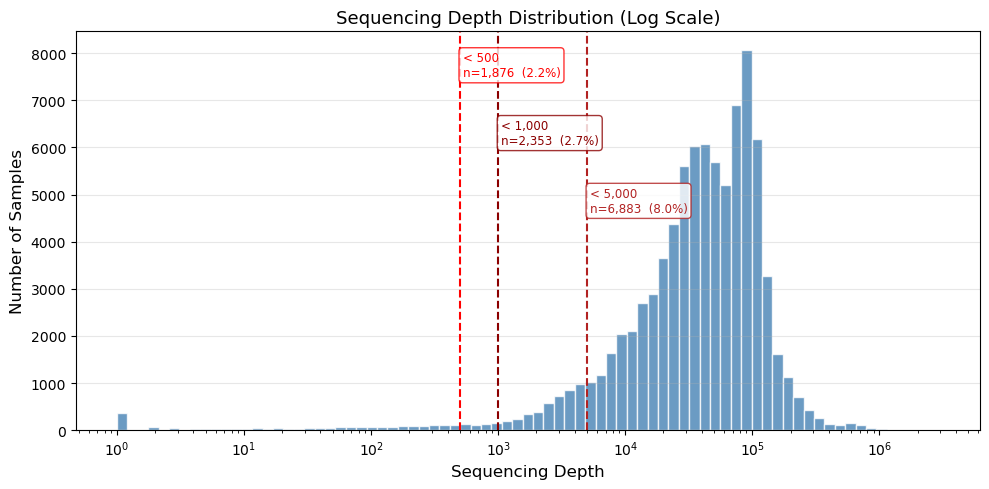

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))

depths = depth_df['reads_depth'].values
cutoffs     = [500, 1000, 5000]
colors      = ['red', 'darkred', 'firebrick']
y_positions = [0.95, 0.78, 0.61]

bins = np.logspace(np.log10(max(depths.min(), 1)),
                   np.log10(depths.max()), 80)

ax.hist(depths, bins=bins, color='steelblue', edgecolor='white', alpha=0.8)
ax.set_xscale('log')
ymax = ax.get_ylim()[1]

for cutoff, color, ypos in zip(cutoffs, colors, y_positions):
    n     = (depths < cutoff).sum()
    ratio = n / len(depths) * 100
    ax.axvline(cutoff, color=color, linewidth=1.5, linestyle='--')
    ax.text(
        cutoff * 1.05,
        ymax * ypos,
        f'< {cutoff:,}\nn={n:,}  ({ratio:.1f}%)',
        color=color, fontsize=8.5,
        ha='left', va='top',
        bbox=dict(fc='white', ec=color, alpha=0.8, pad=3, boxstyle='round,pad=0.3')
    )

ax.set_xlabel('Sequencing Depth', fontsize=12)
ax.set_ylabel('Number of Samples', fontsize=12)
ax.set_title('Sequencing Depth Distribution (Log Scale)', fontsize=13)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('depth_distribution.png', dpi=150)
plt.show()